# Case Study: Exploring Restaurant Tips

A short, end-to-end exploratory analysis using a small offline preview of the public tips dataset.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Case study questions
- How large are the bills and tips in the available observations?
- How does the tip percentage vary by day and meal period?
- What limitations should be stated before generalizing the findings?

**Dataset note:** The local file is a 14-row preview of the `tips` sample dataset maintained in the seaborn-data repository. It is enough to demonstrate the workflow, but it is too small to support strong general conclusions. Set `USE_FULL_DATASET = True` to request the full public CSV when internet access is available.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR_CANDIDATES = [Path.cwd()/"datasets", Path.cwd().parent/"datasets", Path.cwd().parent.parent/"datasets"]
DATA_DIR = next((p for p in DATA_DIR_CANDIDATES if (p/"tips_sample.csv").exists()), DATA_DIR_CANDIDATES[0])
TIPS_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
USE_FULL_DATASET = False  # Set True when online access is available.
if USE_FULL_DATASET:
    tips = pd.read_csv(TIPS_URL)
else:
    tips = pd.read_csv(DATA_DIR/"tips_sample.csv")
print("Rows:", len(tips), "Source mode:", "full public CSV" if USE_FULL_DATASET else "local preview")
display(tips.head())

Rows: 14 Source mode: local preview


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
# Inspect schema and create a derived metric.
print(tips.info())
print("Missing values:\n", tips.isna().sum())
tips["tip_percent"] = 100 * tips["tip"] / tips["total_bill"]
display(tips[["total_bill", "tip", "tip_percent", "day", "time"]].describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  14 non-null     float64
 1   tip         14 non-null     float64
 2   sex         14 non-null     object 
 3   smoker      14 non-null     object 
 4   day         14 non-null     object 
 5   time        14 non-null     object 
 6   size        14 non-null     int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 916.0+ bytes
None
Missing values:
 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


,total_bill,tip,tip_percent
count,14.00,14.00,14.00
mean,19.05,2.81,15.18
std,7.49,1.20,4.40
min,8.77,1.01,5.94
25%,14.84,1.77,13.27
50%,17.71,3.06,15.37
75%,24.36,3.45,16.66
max,35.26,5.00,22.81


,day,time,observations,mean_bill,mean_tip_percent
0,Sun,Dinner,14,19.05,15.18


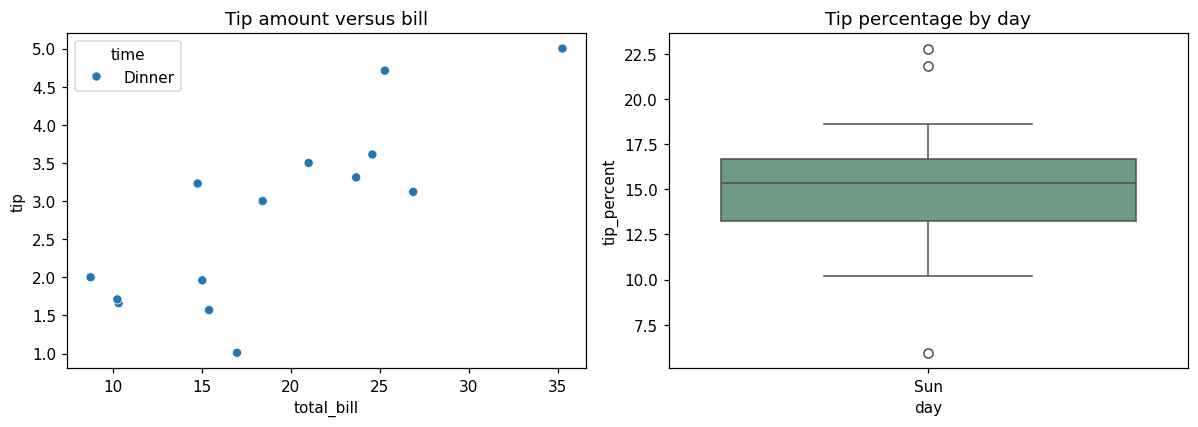

In [3]:
summary = tips.groupby(["day", "time"], as_index=False).agg(
    observations=("tip", "size"), mean_bill=("total_bill", "mean"), mean_tip_percent=("tip_percent", "mean")
)
display(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", ax=axes[0])
axes[0].set_title("Tip amount versus bill")
sns.boxplot(data=tips, x="day", y="tip_percent", color="#66A182", ax=axes[1])
axes[1].set_title("Tip percentage by day")
plt.tight_layout()
plt.show()

## Interpretation checklist
When writing a short report, separate observation from inference. The preview may be ordered by day and contains only a small subset, so group averages can be unstable or unrepresentative. A larger dataset improves precision but does not automatically remove selection bias.

In [4]:
# Compact findings table; values describe only the rows currently loaded.
findings = pd.DataFrame({
    "metric": ["number of rows", "mean bill", "median bill", "mean tip percentage"],
    "value": [len(tips), tips["total_bill"].mean(), tips["total_bill"].median(), tips["tip_percent"].mean()],
})
display(findings.round(2))
print("Caution: the local preview is not representative enough for population-level claims.")

Caution: the local preview is not representative enough for population-level claims.


,metric,value
0,number of rows,14.00
1,mean bill,19.05
2,median bill,17.71
3,mean tip percentage,15.18


## Practice
Add a column for bill size bands, summarize average tip percentage by band, and note the sample size in each band.

In [5]:
tips["bill_band"] = pd.cut(tips["total_bill"], bins=[0, 15, 25, np.inf], labels=["Small", "Medium", "Large"])
answer = tips.groupby("bill_band", observed=False).agg(
    rows=("tip", "size"), mean_tip_percent=("tip_percent", "mean")
).reset_index()
display(answer.round(2))

,bill_band,rows,mean_tip_percent
0,Small,4,19.34
1,Medium,7,12.96
2,Large,3,14.80
